In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision import datasets, transforms, models

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

In [2]:
import kagglehub
path = kagglehub.dataset_download("slothkong/10-monkey-species")

Using Colab cache for faster access to the '10-monkey-species' dataset.


In [3]:
os.listdir('/kaggle/input/10-monkey-species/training/training')

['n8', 'n6', 'n7', 'n1', 'n0', 'n2', 'n5', 'n4', 'n9', 'n3']

In [4]:
training_dataset_path = '/kaggle/input/10-monkey-species/training/training'
testing_dataset_path = '/kaggle/input/10-monkey-species/validation/validation'

In [5]:
train_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_transforms = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [6]:
train_dir = training_dataset_path
val_dir = testing_dataset_path

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transforms
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_transforms
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Classes:", train_dataset.classes)
print("Number of classes:", len(train_dataset.classes))

Classes: ['n0', 'n1', 'n2', 'n3', 'n4', 'n5', 'n6', 'n7', 'n8', 'n9']
Number of classes: 10


In [7]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze feature extractor
for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 10)
)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 115MB/s]


In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=1e-3
)

In [9]:
def train_one_epoch(model, loader):
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (preds == labels).sum().item()

    return running_loss / len(loader), 100 * correct / total

In [10]:
def evaluate(model, loader):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (preds == labels).sum().item()

    return running_loss / len(loader), 100 * correct / total

In [11]:
epochs = 10

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch 1/10 | Train Loss: 1.5105 | Train Acc: 55.33% | Val Loss: 0.6981 | Val Acc: 89.34%
Epoch 2/10 | Train Loss: 0.5363 | Train Acc: 87.51% | Val Loss: 0.2893 | Val Acc: 95.22%
Epoch 3/10 | Train Loss: 0.3003 | Train Acc: 93.25% | Val Loss: 0.2188 | Val Acc: 94.12%
Epoch 4/10 | Train Loss: 0.2225 | Train Acc: 94.53% | Val Loss: 0.1493 | Val Acc: 96.32%
Epoch 5/10 | Train Loss: 0.2004 | Train Acc: 93.53% | Val Loss: 0.1580 | Val Acc: 96.69%
Epoch 6/10 | Train Loss: 0.1680 | Train Acc: 95.99% | Val Loss: 0.1401 | Val Acc: 97.06%
Epoch 7/10 | Train Loss: 0.1246 | Train Acc: 97.08% | Val Loss: 0.1437 | Val Acc: 95.59%
Epoch 8/10 | Train Loss: 0.1282 | Train Acc: 96.44% | Val Loss: 0.1655 | Val Acc: 95.22%
Epoch 9/10 | Train Loss: 0.1382 | Train Acc: 95.35% | Val Loss: 0.1788 | Val Acc: 94.49%
Epoch 10/10 | Train Loss: 0.1193 | Train Acc: 95.99% | Val Loss: 0.1648 | Val Acc: 95.22%


In [12]:
for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5
)

In [13]:
torch.save(
    model.state_dict(),
    "monkey_resnet18.pth"
)

In [14]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=train_dataset.classes
    )
)

              precision    recall  f1-score   support

          n0       0.84      1.00      0.91        26
          n1       1.00      1.00      1.00        28
          n2       1.00      0.96      0.98        27
          n3       1.00      0.97      0.98        30
          n4       0.93      0.96      0.94        26
          n5       1.00      0.86      0.92        28
          n6       0.96      0.96      0.96        26
          n7       1.00      0.93      0.96        28
          n8       0.96      0.96      0.96        27
          n9       0.86      0.92      0.89        26

    accuracy                           0.95       272
   macro avg       0.95      0.95      0.95       272
weighted avg       0.96      0.95      0.95       272



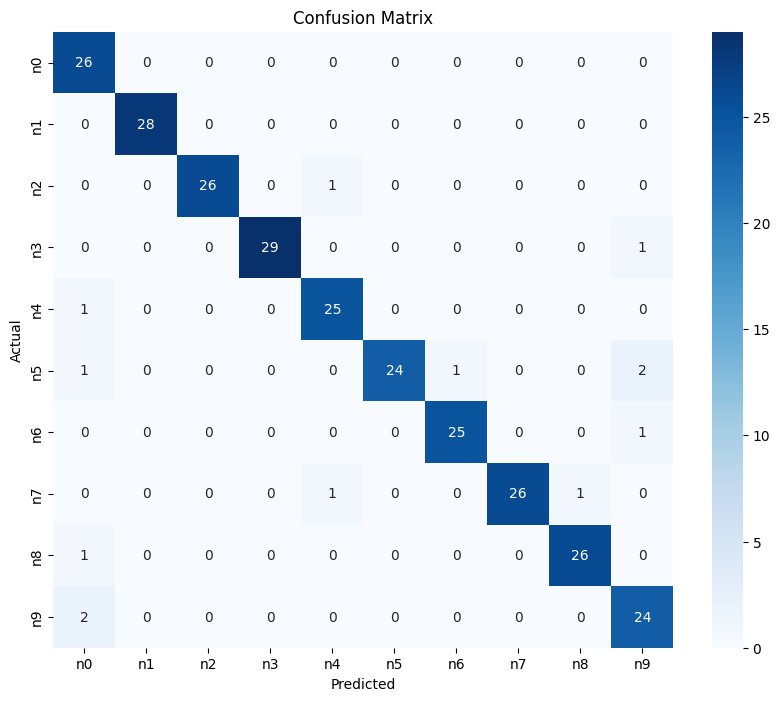

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [21]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle

model.eval()

y_true = []
y_score = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_score.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_score = np.array(y_score)

In [22]:
n_classes = 10

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(n_classes)
)

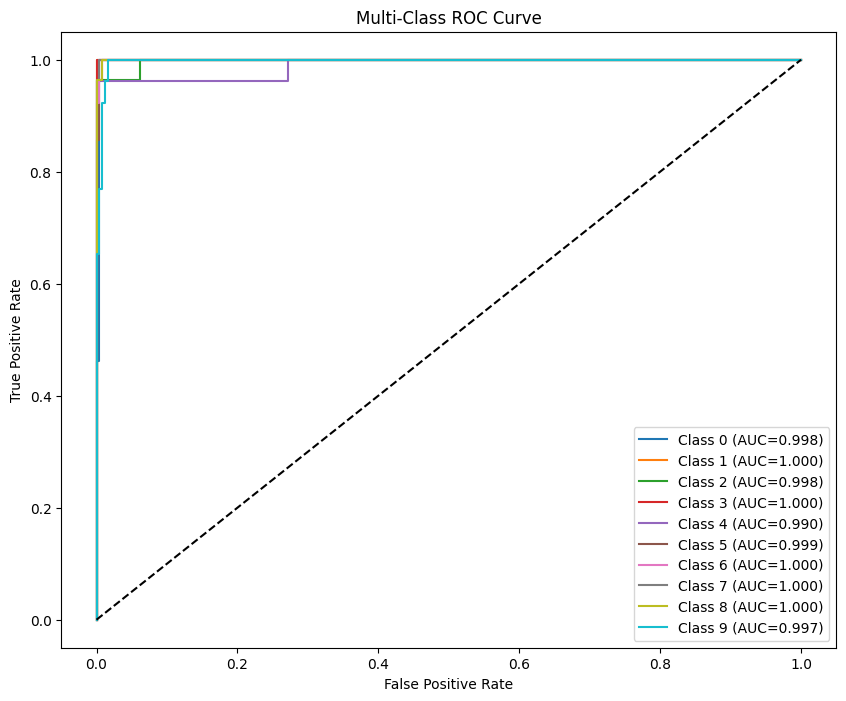

In [23]:
plt.figure(figsize=(10,8))

for i in range(n_classes):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {i} (AUC={roc_auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-Class ROC Curve")
plt.legend()
plt.show()

In [24]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_true_bin,
    y_score,
    multi_class="ovr",
    average="weighted"
)

print("Macro ROC-AUC:", macro_auc)
print("Weighted ROC-AUC:", weighted_auc)

Macro ROC-AUC: 0.99807607435542
Weighted ROC-AUC: 0.9981450477032077
